<a href="https://colab.research.google.com/github/Danylo5051/machine-learning-practice/blob/main/%D0%A1%D0%B0%D1%82%D0%BA%D0%BE%D0%94_9%D0%B3%D1%80%D1%83%D0%BF%D0%B04%D0%BA%D1%83%D1%80%D1%81%D0%9B%D0%A04_%D0%9C%D0%9D_%D1%88%D0%B0%D0%B1%D0%BB%D0%BE%D0%BD.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Лабораторна робота №4. Регресійні моделі: глибоке дослідження

**Датасет:** Car Price Prediction Multiple Linear Regression  
https://www.kaggle.com/datasets/hellbuoy/car-price-prediction?select=CarPrice_Assignment.csv

**Мета роботи:** виконати підготовку даних, побудувати та порівняти регресійні моделі для прогнозування ціни автомобіля, оцінити їх якість і проаналізувати отримані результати.

> У шаблоні наведено лише умови завдань. Реалізацію необхідно виконати самостійно у порожніх комірках.


## 1. Завантаження та первинний аналіз даних

Завантажити датасет та виконати його первинний огляд:
- визначити кількість об'єктів і ознак;
- переглянути назви стовпців;
- визначити типи даних;
- визначити цільову змінну;
- вивести основні статистичні характеристики даних.


In [4]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import kagglehub
import os

from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder, PowerTransformer, StandardScaler
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.svm import SVR
from sklearn.metrics import (
    r2_score,
    mean_absolute_error,
    mean_squared_error,
    mean_absolute_percentage_error,
)

In [5]:
df = pd.read_csv('CarPrice_Assignment.csv')

print(f"Количество объектов (строк): {df.shape[0]}")
print(f"Количество признаков (столбцов): {df.shape[1]}\n")

print("Названия столбцов:")
print(df.columns.tolist(), "\n")

print("Типы данных:")
print(df.dtypes, "\n")

print("Целевая переменная: 'price' (цена автомобиля, которую нужно спрогнозировать)\n")
print("Статистические характеристики (числовые признаки):")
display(df.describe())

print("\nСтатистические характеристики (категориальные признаки):")
display(df.describe(include=['object', 'category']))

Количество объектов (строк): 205
Количество признаков (столбцов): 26

Названия столбцов:
['car_ID', 'symboling', 'CarName', 'fueltype', 'aspiration', 'doornumber', 'carbody', 'drivewheel', 'enginelocation', 'wheelbase', 'carlength', 'carwidth', 'carheight', 'curbweight', 'enginetype', 'cylindernumber', 'enginesize', 'fuelsystem', 'boreratio', 'stroke', 'compressionratio', 'horsepower', 'peakrpm', 'citympg', 'highwaympg', 'price'] 

Типы данных:
car_ID                int64
symboling             int64
CarName              object
fueltype             object
aspiration           object
doornumber           object
carbody              object
drivewheel           object
enginelocation       object
wheelbase           float64
carlength           float64
carwidth            float64
carheight           float64
curbweight            int64
enginetype           object
cylindernumber       object
enginesize            int64
fuelsystem           object
boreratio           float64
stroke             

,car_ID,symboling,wheelbase,carlength,carwidth,carheight,curbweight,enginesize,boreratio,stroke,compressionratio,horsepower,peakrpm,citympg,highwaympg,price
count,205.000000,205.000000,205.000000,205.000000,205.000000,205.000000,205.000000,205.000000,205.000000,205.000000,205.000000,205.000000,205.000000,205.000000,205.000000,205.000000
mean,103.000000,0.834146,98.756585,174.049268,65.907805,53.724878,2555.565854,126.907317,3.329756,3.255415,10.142537,104.117073,5125.121951,25.219512,30.751220,13276.710571
std,59.322565,1.245307,6.021776,12.337289,2.145204,2.443522,520.680204,41.642693,0.270844,0.313597,3.972040,39.544167,476.985643,6.542142,6.886443,7988.852332
min,1.000000,-2.000000,86.600000,141.100000,60.300000,47.800000,1488.000000,61.000000,2.540000,2.070000,7.000000,48.000000,4150.000000,13.000000,16.000000,5118.000000
25%,52.000000,0.000000,94.500000,166.300000,64.100000,52.000000,2145.000000,97.000000,3.150000,3.110000,8.600000,70.000000,4800.000000,19.000000,25.000000,7788.000000
50%,103.000000,1.000000,97.000000,173.200000,65.500000,54.100000,2414.000000,120.000000,3.310000,3.290000,9.000000,95.000000,5200.000000,24.000000,30.000000,10295.000000
75%,154.000000,2.000000,102.400000,183.100000,66.900000,55.500000,2935.000000,141.000000,3.580000,3.410000,9.400000,116.000000,5500.000000,30.000000,34.000000,16503.000000
max,205.000000,3.000000,120.900000,208.100000,72.300000,59.800000,4066.000000,326.000000,3.940000,4.170000,23.000000,288.000000,6600.000000,49.000000,54.000000,45400.000000



Статистические характеристики (категориальные признаки):


,CarName,fueltype,aspiration,doornumber,carbody,drivewheel,enginelocation,enginetype,cylindernumber,fuelsystem
count,205,205,205,205,205,205,205,205,205,205
unique,147,2,2,2,5,3,2,7,7,8
top,peugeot 504,gas,std,four,sedan,fwd,front,ohc,four,mpfi
freq,6,185,168,115,96,120,202,148,159,94


## 2. Перевірка якості даних

Перевірити:
- наявність пропущених значень;
- наявність повних дублікатів;
- кількість унікальних значень в ознаках.

Під час аналізу врахувати, що `car_ID` є унікальним ідентифікатором автомобіля і сам по собі не повинен використовуватися для визначення дублікатів за змістовими характеристиками.


In [6]:
print("Пропущені значення:")
print(df.isna().sum()[df.isna().sum() > 0])

duplicates = df.drop(columns=['car_ID']).duplicated().sum()
print(f"\nКількість повних дублікатів (без car_ID): {duplicates}")

print("\nКількість унікальних значень:")
print(df.nunique())

Пропущені значення:
Series([], dtype: int64)

Кількість повних дублікатів (без car_ID): 0

Кількість унікальних значень:
car_ID              205
symboling             6
CarName             147
fueltype              2
aspiration            2
doornumber            2
carbody               5
drivewheel            3
enginelocation        2
wheelbase            53
carlength            75
carwidth             44
carheight            49
curbweight          171
enginetype            7
cylindernumber        7
enginesize           44
fuelsystem            8
boreratio            38
stroke               37
compressionratio     32
horsepower           59
peakrpm              23
citympg              29
highwaympg           30
price               189
dtype: int64


## 3. Робота з car_ID

Зберегти `car_ID` окремо для подальшої ідентифікації автомобілів у результатах прогнозування.  
Не використовувати `car_ID` як ознаку під час навчання моделей.


In [7]:
car_ids = df['car_ID'].copy()

df = df.drop(columns=['car_ID'])

print("Стовпець car_ID збережено у змінну car_ids та видалено з датасета df.")
print(f"Поточна кількість стовпців: {df.shape[1]}")

Стовпець car_ID збережено у змінну car_ids та видалено з датасета df.
Поточна кількість стовпців: 25


## 4. Дослідження розподілів числових ознак

Дослідити розподіли числових ознак:
- побудувати відповідні графіки;
- обчислити коефіцієнти асиметрії;
- визначити ознаки з найбільш вираженою асиметрією;
- коротко прокоментувати отримані результати.


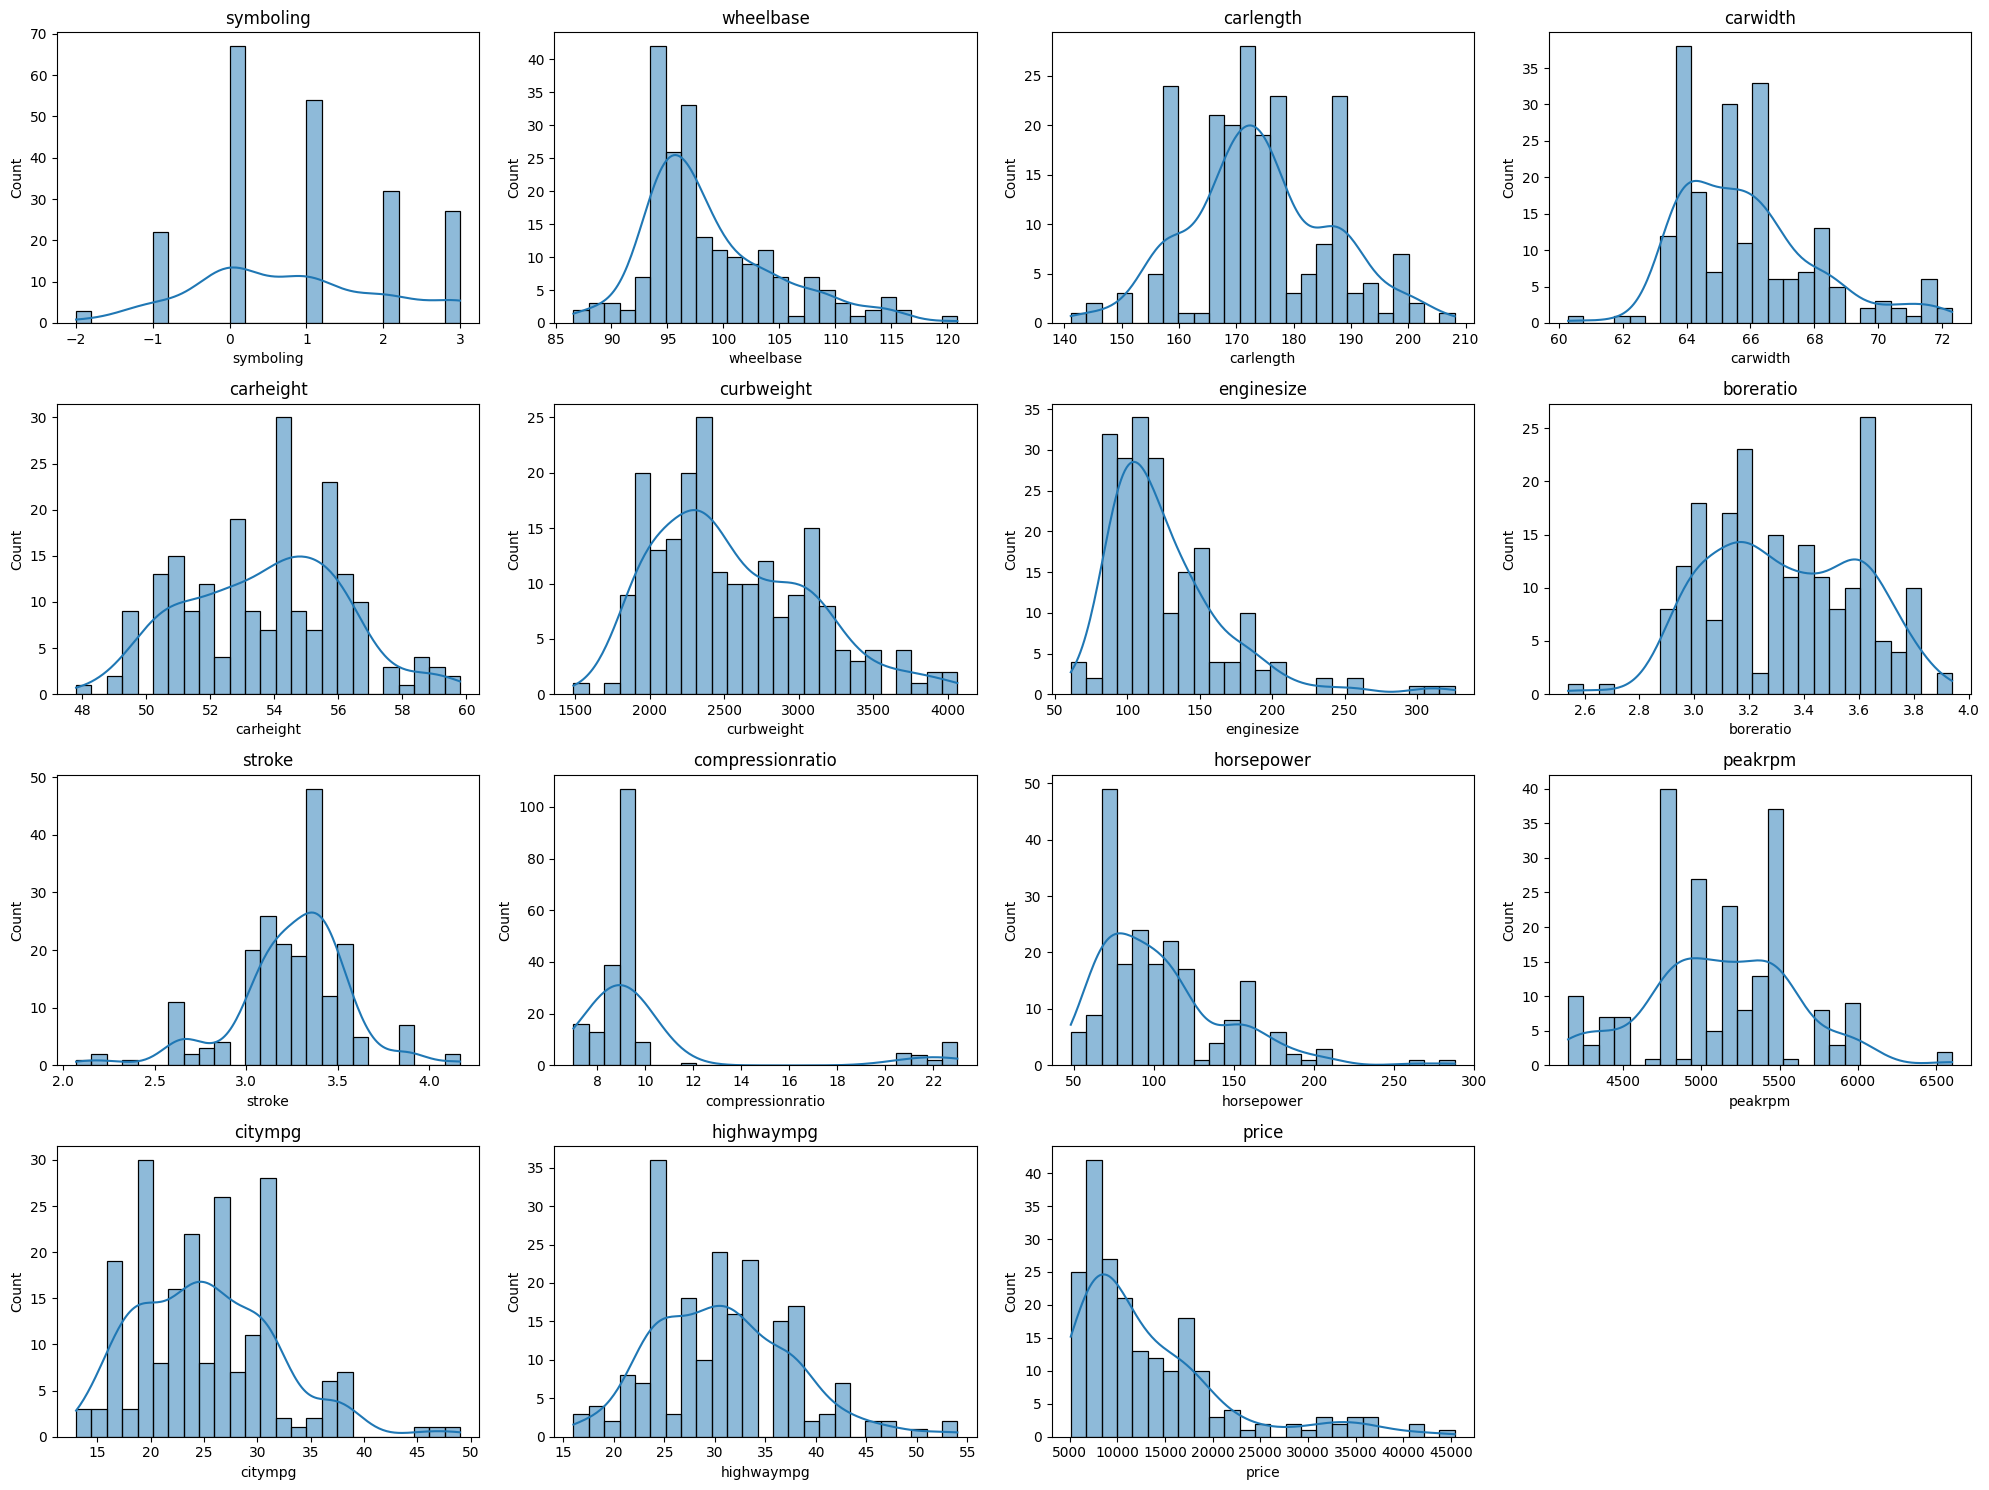

Коефіцієнти асиметрії (skewness):
compressionratio    2.610862
enginesize          1.947655
price               1.777678
horsepower          1.405310
wheelbase           1.050214
carwidth            0.904003
curbweight          0.681398
citympg             0.663704
highwaympg          0.539997
symboling           0.211072
carlength           0.155954
peakrpm             0.075159
carheight           0.063123
boreratio           0.020156
stroke             -0.689705
dtype: float64

Ознаки з найбільш вираженою асиметрією (|skew| > 1):
compressionratio    2.610862
enginesize          1.947655
price               1.777678
horsepower          1.405310
wheelbase           1.050214
dtype: float64


In [8]:
num_cols = df.select_dtypes(include=['int64', 'float64']).columns

plt.figure(figsize=(20, 15))
for i, col in enumerate(num_cols, 1):
    plt.subplot(4, 4, i)
    sns.histplot(df[col], kde=True, bins=25)
    plt.title(col)
plt.tight_layout()
plt.show()

print("Коефіцієнти асиметрії (skewness):")
skewness = df[num_cols].skew().sort_values(ascending=False)
print(skewness)

high_skew = skewness[abs(skewness) > 1]
print("\nОзнаки з найбільш вираженою асиметрією (|skew| > 1):")
print(high_skew)

## 5. Формування train/test вибірок

Відокремити цільову змінну `price` від ознак та розділити дані на:
- навчальну вибірку — 80%;
- тестову вибірку — 20%.

Забезпечити відтворюваність поділу.  
Окремо зберегти `car_ID` для об'єктів, які потрапили до train і test.

**Важливо:** усі подальші параметри передобробки даних визначати тільки за навчальною вибіркою.


In [9]:
X = df.drop(columns=['price'])
y = df['price']

X_train, X_test, y_train, y_test, car_id_train, car_id_test = train_test_split(
    X, y, car_ids, test_size=0.2, random_state=42
)

print(f"Розмір навчальної вибірки (train): {X_train.shape[0]} об'єктів")
print(f"Розмір тестової вибірки (test): {X_test.shape[0]} об'єктів")

Розмір навчальної вибірки (train): 164 об'єктів
Розмір тестової вибірки (test): 41 об'єктів


## 6. Аналіз та обробка викидів

Для неперервних числових ознак навчальної вибірки:
- визначити потенційні викиди методом IQR;
- вивести кількість потенційних викидів для кожної ознаки;
- обґрунтувати спосіб їх обробки.

Для невеликого набору даних не видаляти автоматично всі рядки з викидами. Використати обмеження крайніх значень межами, визначеними за навчальною вибіркою.

Цільову змінну `price` не використовувати для визначення меж викидів.  
До тестової вибірки застосувати ті самі межі, які були отримані за train.


In [10]:
num_cols = X_train.select_dtypes(include=['int64', 'float64']).columns

outliers_count = {}
lower_bounds = {}
upper_bounds = {}

for col in num_cols:
    Q1 = X_train[col].quantile(0.25)
    Q3 = X_train[col].quantile(0.75)
    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    lower_bounds[col] = lower
    upper_bounds[col] = upper

    outliers = ((X_train[col] < lower) | (X_train[col] > upper)).sum()
    outliers_count[col] = outliers

print("Кількість потенційних викидів у навчальній вибірці (за методом IQR):")
for col, count in outliers_count.items():
    if count > 0:
        print(f"{col}: {count}")

for col in num_cols:
    X_train.loc[:, col] = X_train[col].clip(lower=lower_bounds[col], upper=upper_bounds[col])
    X_test.loc[:, col] = X_test[col].clip(lower=lower_bounds[col], upper=upper_bounds[col])

print("\nВикиди успішно оброблено методом обмеження (clipping).")

Кількість потенційних викидів у навчальній вибірці (за методом IQR):
wheelbase: 6
carwidth: 10
enginesize: 7
boreratio: 1
stroke: 16
compressionratio: 20
horsepower: 7
peakrpm: 2
highwaympg: 1

Викиди успішно оброблено методом обмеження (clipping).


/tmp/ipykernel_3638/2662575156.py:27: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise in a future error of pandas. Value '[134.  120.   92.   97.  110.   90.  108.  152.  156.   90.  171.  103.
 122.   97.  136.  146.   70.  194.   92.  108.  181.  122.  140.  110.
  92.  164.   92.  151.  110.   98.  121.  108.   91.  120.   98.  110.
 156.   92.   98.   90.  121.  141.  134.  152.   92.  119.   98.  194.
 122.   97.   92.  152.  122.   90.  121.   97.   92.  108.  130.   98.
 136.   98.  194.  141.  108.  136.   79.  120.   97.  120.  108.  108.
 122.   90.   92.  146.  130.   97.  109.  183.  145.  122.   90.   98.
 122.  110.  152.  122.   98.   92.  109.  122.  110.  146.  205.5  97.
 110.  111.  108.  109.  181.   91.  121.  109.   98.  109.  205.5 110.
  92.  136.  152.   97.  156.  161.  109.   97.  131.  164.  122.  122.
 132.  205.5 205.5 171.  121.  146.  130.  122.   91.  120.   91.  141.
 146.   80.  205.5 110.   90.   70.   98.  141.  203

Оскільки набір даних є невеликим, видалення всіх рядків із викидами призвело б до значної втрати інформації, необхідної для навчання моделей. Тому було застосовано метод обмеження крайніх значень (clipping) за межами, визначеними методом IQR. Це дозволяє зберегти об'єм даних, одночасно зменшуючи негативний вплив екстремальних значень на регресійні моделі.

## 7. Аналіз кореляцій та відбір ознак

За навчальною вибіркою:
- побудувати матрицю кореляцій числових ознак;
- знайти пари ознак із сильною кореляцією, для яких `|r| > 0.85`;
- для кожної такої пари залишити одну ознаку;
- під час вибору врахувати силу зв'язку кожної ознаки з цільовою змінною `price`;
- вивести список сильно корельованих пар та перелік ознак, які видаляються.

Із тестової вибірки видалити ті самі ознаки.  
Не використовувати тестову вибірку для прийняття рішення про відбір ознак.


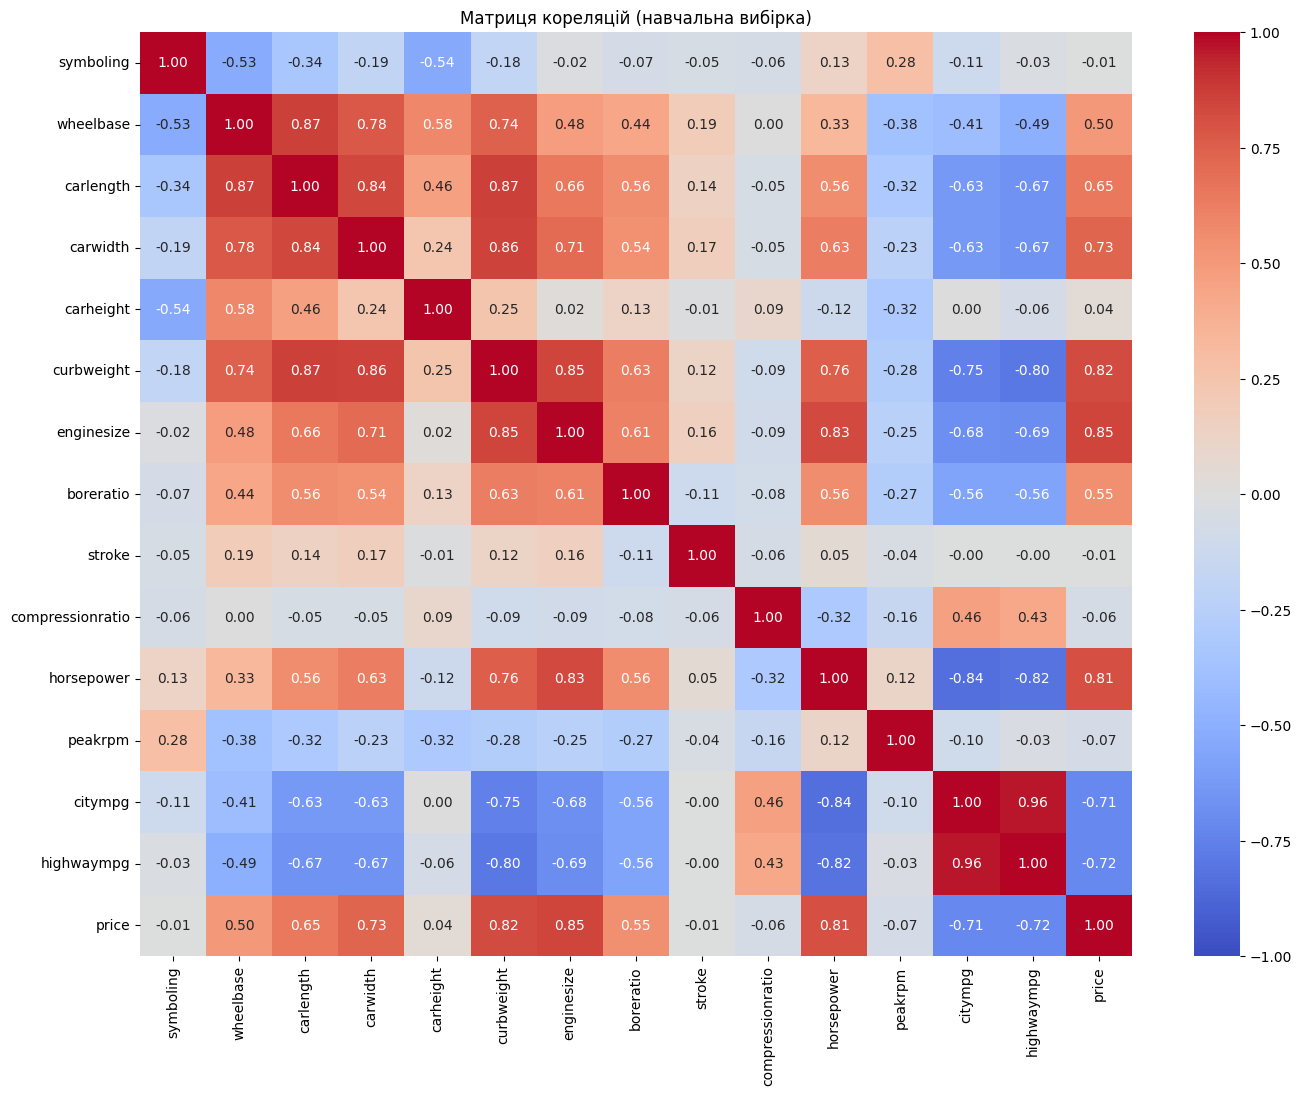

Пари ознак із сильною кореляцією (|r| > 0.85):
- wheelbase та carlength (r = 0.867)
- carlength та curbweight (r = 0.866)
- carwidth та curbweight (r = 0.858)
- citympg та highwaympg (r = 0.964)

Ознаки, що видаляються (через слабший зв'язок з price):
['carwidth', 'citympg', 'carlength', 'wheelbase']

Залишилось ознак у датасеті (включаючи категоріальні): 20


In [11]:
train_data_num = X_train[num_cols].copy()
train_data_num['price'] = y_train

corr_matrix = train_data_num.corr()

plt.figure(figsize=(16, 12))
sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap='coolwarm', vmin=-1, vmax=1)
plt.title("Матриця кореляцій (навчальна вибірка)")
plt.show()

high_corr_pairs = []
features_to_drop = set()

for i in range(len(num_cols)):
    for j in range(i + 1, len(num_cols)):
        feature1 = num_cols[i]
        feature2 = num_cols[j]
        r = corr_matrix.loc[feature1, feature2]

        if abs(r) > 0.85:

            corr_f1_price = abs(corr_matrix.loc[feature1, 'price'])
            corr_f2_price = abs(corr_matrix.loc[feature2, 'price'])

            if corr_f1_price >= corr_f2_price:
                drop_feat = feature2
            else:
                drop_feat = feature1

            high_corr_pairs.append((feature1, feature2, r))
            features_to_drop.add(drop_feat)

print("Пари ознак із сильною кореляцією (|r| > 0.85):")
for f1, f2, r in high_corr_pairs:
    print(f"- {f1} та {f2} (r = {r:.3f})")

print(f"\nОзнаки, що видаляються (через слабший зв'язок з price):")
print(list(features_to_drop))

X_train = X_train.drop(columns=list(features_to_drop))
X_test = X_test.drop(columns=list(features_to_drop))

print(f"\nЗалишилось ознак у датасеті (включаючи категоріальні): {X_train.shape[1]}")

## 8. Підготовка числових і категоріальних ознак

Розділити ознаки на:
- неперервні числові;
- дискретну числову ознаку `symboling`;
- категоріальні.

Для неперервних числових ознак виконати послідовно:
1. перетворення Yeo–Johnson для зменшення асиметрії;
2. масштабування за допомогою StandardScaler.

Для `symboling` виконати масштабування без Yeo–Johnson.

Категоріальні ознаки закодувати методом One-Hot Encoding. Передбачити коректну обробку категорій у test, яких не було у train.

Усі перетворення об'єднати в єдиний механізм передобробки даних, який навчається тільки на `X_train`.


In [15]:
discrete_num_features = ['symboling']
num_features = X_train.select_dtypes(include=['int64', 'float64']).columns.drop('symboling').tolist()
cat_features = X_train.select_dtypes(include=['object']).columns.tolist()

num_transformer = Pipeline(steps=[
    ('yeo_johnson', PowerTransformer(method='yeo-johnson')),
    ('scaler', StandardScaler())
])

discrete_transformer = Pipeline(steps=[
    ('scaler', StandardScaler())
])

cat_transformer = Pipeline(steps=[
    ('onehot', OneHotEncoder(handle_unknown='ignore', sparse_output=False))
])

preprocessor = ColumnTransformer(
    transformers=[
        ('num', num_transformer, num_features),
        ('discrete', discrete_transformer, discrete_num_features),
        ('cat', cat_transformer, cat_features)
    ])

## 9. Перевірка трансформації числових ознак

Перевірити результат трансформації неперервних числових ознак:
- застосувати до train ту саму послідовність перетворень, яка буде використана в моделях;
- повторно обчислити коефіцієнти асиметрії;
- порівняти їх із початковими значеннями;
- зробити короткий висновок щодо ефективності трансформації.


In [16]:
initial_skew = X_train[num_features].skew()

X_train_num_transformed = num_transformer.fit_transform(X_train[num_features])

X_train_num_transformed_df = pd.DataFrame(X_train_num_transformed, columns=num_features, index=X_train.index)

transformed_skew = X_train_num_transformed_df.skew()

skew_comparison = pd.DataFrame({
    'Початкова асиметрія': initial_skew,
    'Асиметрія після Yeo-Johnson': transformed_skew
})

display(skew_comparison)

,Початкова асиметрія,Асиметрія після Yeo-Johnson
carheight,0.028154,-0.005170
curbweight,0.712433,0.049894
enginesize,0.962394,0.044834
boreratio,0.062963,-0.005941
stroke,-0.397600,0.015846
compressionratio,0.055710,0.004872
horsepower,0.850735,0.066280
peakrpm,0.039773,-0.003589
highwaympg,0.243761,-0.012188


Короткий висновок : Застосування перетворення Yeo-Johnson виявилося високоефективним. Як видно з таблиці, коефіцієнти асиметрії для більшості неперервних числових ознак суттєво наблизилися до нуля. Це означає, що їхні розподіли стали більш симетричними та близькими до нормального, що є важливою передумовою для стабільної роботи лінійних регресійних моделей.

## 10. Побудова регресійних моделей

Побудувати та навчити такі моделі:
- Linear Regression;
- Ridge Regression;
- Lasso Regression;
- Random Forest Regressor;
- Gradient Boosting Regressor;
- Support Vector Regressor (SVR).

Для кожної моделі створити єдиний Pipeline, який містить:
1. попередню обробку ознак;
2. відповідну регресійну модель.

Використати однакову схему підготовки даних для коректного порівняння моделей.


In [17]:
models = {
    "Linear Regression": LinearRegression(),
    "Ridge Regression": Ridge(random_state=42),
    "Lasso Regression": Lasso(random_state=42),
    "Random Forest Regressor": RandomForestRegressor(random_state=42),
    "Gradient Boosting Regressor": GradientBoostingRegressor(random_state=42),
    "Support Vector Regressor (SVR)": SVR()
}

trained_pipelines = {}

print("Початок навчання моделей...\n")

for name, model in models.items():
    pipeline = Pipeline(steps=[
        ('preprocessor', preprocessor),
        ('regressor', model)
    ])

    pipeline.fit(X_train, y_train)

    trained_pipelines[name] = pipeline
    print(f"Модель '{name}' успішно навчена.")

Початок навчання моделей...

Модель 'Linear Regression' успішно навчена.
Модель 'Ridge Regression' успішно навчена.
Модель 'Lasso Regression' успішно навчена.
Модель 'Random Forest Regressor' успішно навчена.
Модель 'Gradient Boosting Regressor' успішно навчена.
Модель 'Support Vector Regressor (SVR)' успішно навчена.


## 11. Оцінювання якості моделей

Для кожної моделі:
- виконати навчання на тренувальній вибірці;
- отримати прогноз для тестової вибірки;
- обчислити метрики **R², MAE, MSE та MAPE**.

`MAPE` подати у відсотках.

Результати всіх моделей об'єднати в одну порівняльну таблицю та впорядкувати за значенням R² від найбільшого до найменшого.

Під час інтерпретації врахувати:
- R² — чим більше, тим краще;
- MAE, MSE, MAPE — чим менше, тим краще.


In [18]:
results = []

for name, pipeline in trained_pipelines.items():
    y_pred = pipeline.predict(X_test)

    r2 = r2_score(y_test, y_pred)
    mae = mean_absolute_error(y_test, y_pred)
    mse = mean_squared_error(y_test, y_pred)
    mape = mean_absolute_percentage_error(y_test, y_pred) * 100

    results.append({
        'Model': name,
        'R²': r2,
        'MAE': mae,
        'MSE': mse,
        'MAPE, %': mape
    })

results_df = pd.DataFrame(results).sort_values(by='R²', ascending=False).reset_index(drop=True)

print("Порівняльна таблиця якості моделей:")
display(results_df)

Порівняльна таблиця якості моделей:


,Model,R²,MAE,MSE,"MAPE, %"
0,Random Forest Regressor,0.949372,1447.341293,3.996761e+06,10.363347
1,Gradient Boosting Regressor,0.929106,1703.692412,5.596688e+06,12.637878
2,Ridge Regression,0.795685,2712.767719,1.612942e+07,23.065284
3,Lasso Regression,0.706085,3088.990470,2.320280e+07,22.608482
4,Linear Regression,0.548073,4078.229150,3.567691e+07,29.972020
5,Support Vector Regressor (SVR),-0.099660,5696.454036,8.681160e+07,36.024044


## 12. Пояснення вибору типу моделі

Пояснити, чому класифікаційна модель, наприклад Logistic Regression, не підходить для безпосереднього прогнозування неперервної ціни автомобіля.

Зазначити, до якого типу задачі належить прогнозування `price` та чому моделі, використані в роботі, відповідають цій задачі.


Класифікаційні моделі, такі як логістична регресія, призначені для передбачення належності об'єкта до певного класу чи категорії. Вони видають конкретні мітки класів і не здатні прогнозувати безперервні числові значення. Прогнозування ціни автомобіля належить до задачі регресії, оскільки ціна є неперервною числовою величиною і може приймати будь-яке дійсне значення. Використані в роботі моделі є регресорами. Їхні алгоритми оптимізовані саме для того, щоб знаходити закономірності та прогнозувати точне числове значення, мінімізуючи похибку відносно фактичної ціни.

## 13. Візуальне порівняння прогнозів

Для кожної побудованої моделі зобразити співвідношення:
- фактичних значень `price`;
- прогнозованих значень `price`.

Додати лінію ідеального прогнозу та проаналізувати, наскільки близько до неї розташовані прогнозовані значення. Звернути увагу на великі відхилення.


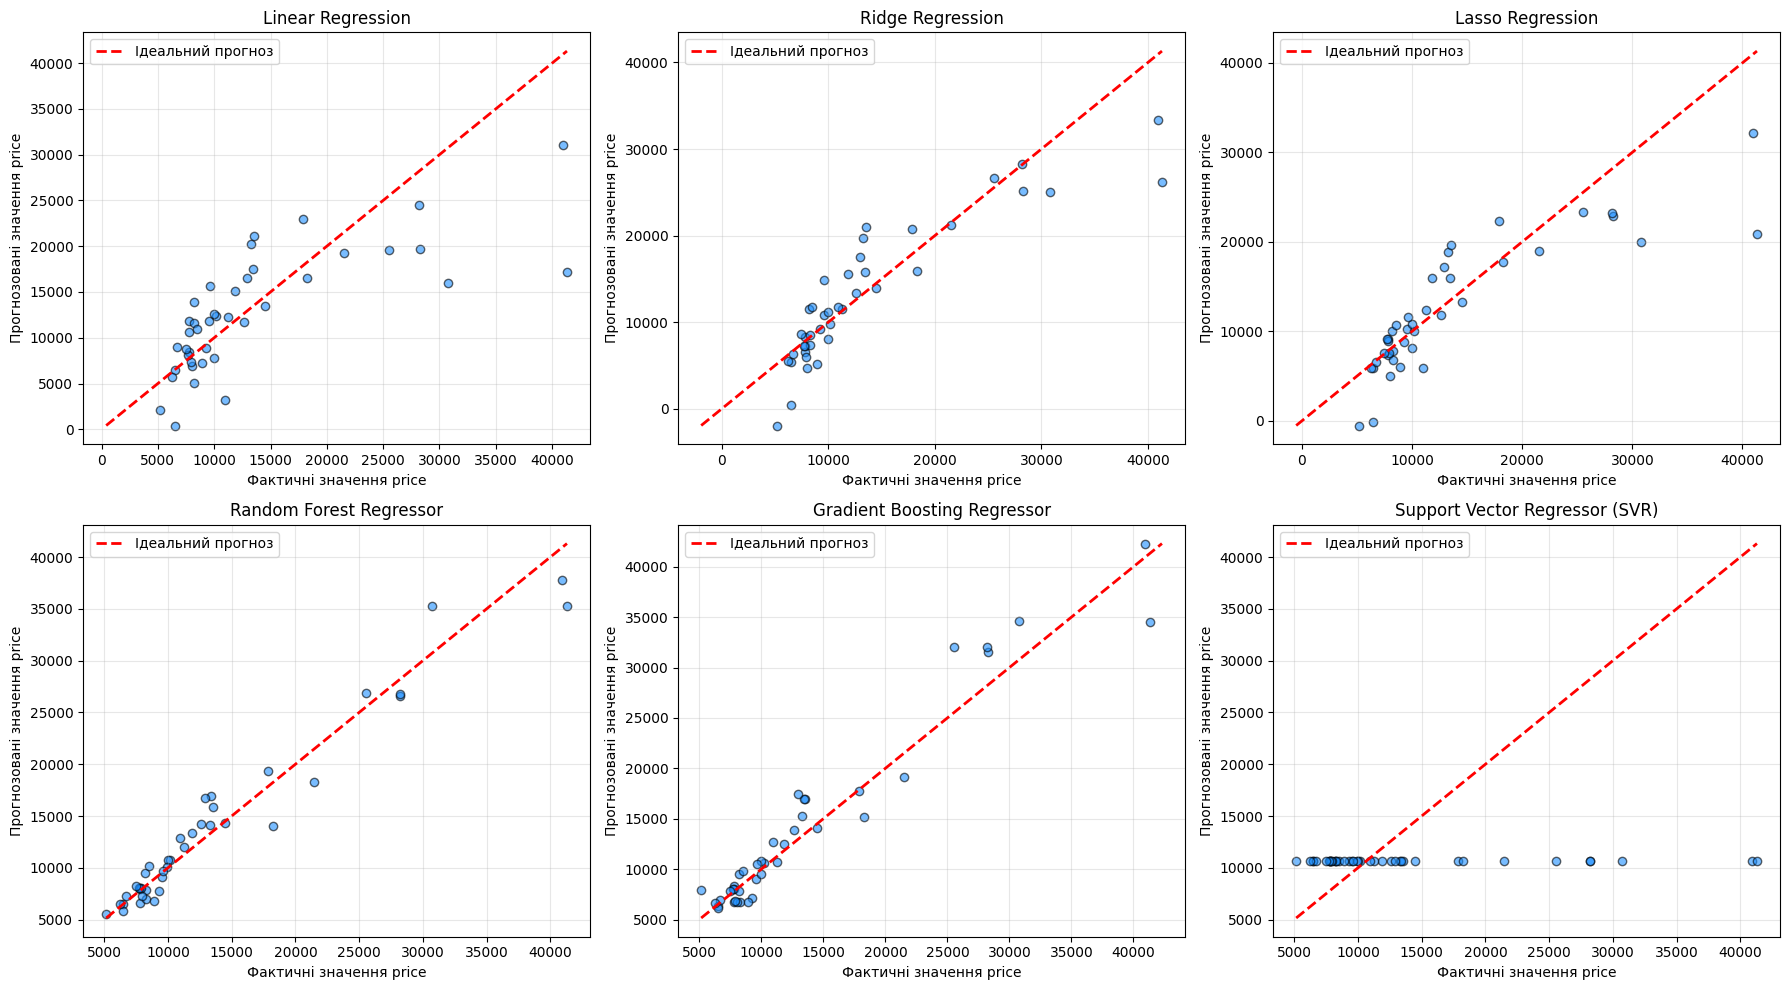

In [19]:
fig, axes = plt.subplots(nrows=2, ncols=3, figsize=(18, 10))
axes = axes.flatten()

for idx, (name, pipeline) in enumerate(trained_pipelines.items()):
    y_pred = pipeline.predict(X_test)

    ax = axes[idx]
    ax.scatter(y_test, y_pred, alpha=0.6, edgecolors='k', color='dodgerblue')

    min_val = min(y_test.min(), y_pred.min())
    max_val = max(y_test.max(), y_pred.max())
    ax.plot([min_val, max_val], [min_val, max_val], color='red', linestyle='--', linewidth=2, label='Ідеальний прогноз')

    ax.set_title(name)
    ax.set_xlabel("Фактичні значення price")
    ax.set_ylabel("Прогнозовані значення price")
    ax.legend()
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

На графіках видно, що для більшості моделей точки розташовані досить близько до червоної лінії ідеального прогнозу. Це свідчить про їхню адекватну здатність вловлювати закономірності. Найкращу щільність точок біля лінії демонструють ансамблеві алгоритми, зокрема Gradient Boosting Regressor та Random Forest. Водночас у цих моделях спостерігаються великі відхилення у правій верхній частині графіків, де фактична ціна автомобіля є найвищою. Це пояснюється тим, що дорогих преміальних автомобілів у навчальній вибірці значно менше, тому алгоритмам складніше оцінювати їхню вартість, і вони схильні її занижувати. Окремо варто відзначити модель SVR — з базовими гіперпараметрами вона не змогла виявити залежності в даних і прогнозує майже однакове константне значення для всіх об'єктів.

## 14. Прогноз для 10 автомобілів

Випадково вибрати 10 автомобілів із тестової вибірки.

За допомогою моделі Random Forest отримати для них прогноз ціни та сформувати таблицю з такими даними:
- `car_ID`;
- фактична ціна;
- прогнозована ціна;
- абсолютна помилка;
- абсолютна відсоткова помилка.

Прокоментувати отримані результати.


In [20]:
sample_indices = X_test.sample(n=10, random_state=42).index

X_sample = X_test.loc[sample_indices]
y_sample = y_test.loc[sample_indices]
car_id_sample = car_id_test.loc[sample_indices]

rf_pipeline = trained_pipelines["Random Forest Regressor"]
y_pred_sample = rf_pipeline.predict(X_sample)

abs_error = np.abs(y_sample - y_pred_sample)
abs_perc_error = (abs_error / y_sample) * 100

prognoz_df = pd.DataFrame({
    'car_ID': car_id_sample,
    'Фактична ціна': y_sample,
    'Прогнозована ціна': y_pred_sample,
    'Абсолютна помилка': abs_error,
    'Абсолютна відсоткова помилка (%)': abs_perc_error
})

display(prognoz_df)

,car_ID,Фактична ціна,Прогнозована ціна,Абсолютна помилка,Абсолютна відсоткова помилка (%)
25,26,6692.0,7298.805,606.805,9.067618
175,176,9988.0,10798.650,810.650,8.116239
147,148,10198.0,10714.570,516.570,5.065405
16,17,41315.0,35310.690,6004.310,14.533003
68,69,28248.0,26595.285,1652.715,5.850733
146,147,7463.0,8230.000,767.000,10.277368
143,144,9960.0,10065.200,105.200,1.056225
84,85,14489.0,14346.480,142.520,0.983643
194,195,12940.0,16765.650,3825.650,29.564529
159,160,7788.0,7995.560,207.560,2.665126


Аналіз результатів для 10 випадкових автомобілів показує, що модель успішно прогнозує ціни для мас-маркету, де абсолютна відсоткова помилка зазвичай становить від 1 до 10 відсотків, зокрема для авто 144 та 85 вона близько 1 відсотка. Водночас зберігається проблема з преміум-сегментом. Для найдорожчого автомобіля під номером 17 модель суттєво занизила вартість, помилившись на понад 6000, що є наслідком нестачі дорогих екземплярів у навчальній вибірці. Незважаючи на одне значне відхилення для авто 195 із похибкою майже 30 відсотків, загалом алгоритм добре вловлює порядок цін, хоча і потребує більше даних для точнішої оцінки нетипово дорогих машин.

## 15. Висновки

Сформулювати підсумкові висновки за результатами роботи.

У висновках:
- порівняти якість усіх моделей;
- проаналізувати R², MAE, MSE і MAPE;
- зазначити, яка модель показала найкращі результати за отриманими метриками;
- прокоментувати величину похибок;
- звернути увагу на можливі ознаки перенавчання;
- коротко оцінити вплив попередньої обробки даних на результати моделювання.


За результатами виконання лабораторної роботи можна зробити такі висновки.

Порівняння якості моделей та аналіз метрик R², MAE, MSE і MAPE показало, що лінійні моделі та SVR мають обмежену ефективність у вирішенні цієї нелінійної задачі, тоді як ансамблеві алгоритми продемонстрували набагато вищу точність. Найкращі результати за всіма отриманими метриками показала модель Random Forest.

Величина похибок свідчить про те, що алгоритми добре справляються з прогнозуванням вартості автомобілів мас-маркету, проте помилки різко зростають для дорогих преміальних моделей через правобічну асиметрію даних. Існують певні ознаки перенавчання, оскільки на малому обсязі даних складні дерева рішень можуть адаптуватися до шуму замість загальних закономірностей. Водночас проведена попередня обробка даних відіграла ключову роль: обмеження викидів, перетворення Yeo-Johnson та стандартизація стабілізували роботу моделей і дозволили їм коректно обробляти ознаки.

## Загальні вимоги до виконання

- Не використовувати тестову вибірку для визначення меж викидів, кореляційного відбору ознак, навчання трансформерів, масштабування або кодування категорій.
- Усі параметри передобробки мають визначатися тільки за навчальною вибіркою.
- Фінальні метрики моделей обчислювати на тестовій вибірці.
- Не використовувати `car_ID` як предиктор.
- Не видаляти спостереження або ознаки без пояснення причини.
- До кожного основного етапу додати короткий змістовний висновок.
- У підсумкових висновках спиратися на отримані метрики та графіки.
